In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# CPU and RAM health

Does a scope's board compute correctly, keep its full speed and stay cool under a sustained full load? This
notebook reads one standard one-hour run per scope, gives each board a verdict, and compares processor and
memory speed across the fleet.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/cpu_ram_health.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/cpu_ram_health.py),
protocol `cpu_ram_health/2`. `install_requirements()` once per scope (stress-ng, sysbench and smartmontools, with
apt), then `create_exp()` and `start()`. No acquisition may run at the same time. About 2 h 8 min per scope:

1. **Settle**, 60 s idle. Refused if anything else uses more than 10% of the CPU.
2. **Speed**, sysbench, 3 × 20 s each: CPU on 1 and on 4 threads; RAM write and read on 4 threads with 16 MiB
   blocks, larger than the 1 MiB L2 cache, so the RAM is measured and not the cache.
3. **Stress**, stress-ng, 120 min: 4 CPU workers cycling through every CPU method, plus 1 memory worker cycling
   through every memory pattern on a fixed 5 GiB. Every result is checked against the known answer (`--verify`).
4. **Cooldown**, 2 min idle.

Clock, throttle flags, SoC temperature, fan, memory and swap are logged once a second throughout, the SSD's own
temperature sensor once a minute (the test puts no load on the SSD, so any rise is heat from the board), and the
kernel log is kept. The parameters are fixed in the script; a run with any of them changed is marked non-standard.
Protocol `/1` had a 60 min stress phase and no SSD temperature; both versions can be read here.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [2]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [3]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rich, yaml
from scipy.optimize import curve_fit
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA",
                      "/Users/byatharth/data/2026_11_22_diagnostics_after_longrun")   # set to your own runs
KIND = "cpu_ram_health"                                 # only run folders with this in their name
OUT = "results"                                         # the fleet table is written here
HOT_C = 80                                              # the Pi 4 starts slowing itself down here
SCOPES = [f"M{i}" for i in range(1, 9)]
COLORS = dict(zip(SCOPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                           "#e87ba4", "#008300", "#6250d6", "#e34948"]))
TESTS = {"cpu_1t": "CPU, 1 thread", "cpu_4t": "CPU, 4 threads",
         "mem_write_4t": "RAM write", "mem_read_4t": "RAM read"}
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. Only folders with `KIND` in
their name are used, so `DATA` may hold other runs too. One row per run. The `speed` stream has one row per
sysbench repeat (`test, unit, repeat, value`).

In [4]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))

runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "dir": exps.get_parent_dir(eid)}
                     for eid, d in exps.data.items() if KIND in d["metadata"]["name"]])
runs = runs.sort_values(["scope", "started"])
runs["run"] = runs.groupby("scope").cumcount() + 1
runs = runs.set_index(["scope", "run"])
res = res[res.eid.isin(runs.eid)]
key_of = {eid: k for k, eid in runs.eid.items()}
runs["speed_rows"] = runs.eid.map(res[res.stream == "speed"].groupby("eid").size()).fillna(0).astype(int)
present = [s for s in SCOPES if s in runs.index.get_level_values("scope")]
runs.drop(columns="dir")

<Experiments :: 15  datasets [extended_parse]>
  |- eid: 070d927659
  	|- m-stream: findings
  |- eid: e832de00ef
  	|- m-stream: findings
  |- eid: d38bf78ca4
  	|- m-stream: speed
  |- eid: 5b2ea3e731
  	|- m-stream: findings
  |- eid: 4b14166eee
  	|- m-stream: findings
  |- eid: b32e126144
  	|- m-stream: findings
  |- eid: 4d962dbdc4
  	|- m-stream: findings
  |- eid: b2c6a2f030
  	|- m-stream: speed
  |- eid: 42f4e58e70
  	|- m-stream: speed
  |- eid: 93fa480544
  	|- m-stream: speed
  |- eid: 1787af3c61
  	|- m-stream: speed
  |- eid: 6faed330aa
  	|- m-stream: speed
  |- eid: 8891d6ebf2
  	|- m-stream: speed
  |- eid: ac2059b453
  	|- m-stream: findings
  |- eid: b0f3f80ada
  	|- m-stream: speed



,,eid,started,speed_rows
scope,run,,,
M1,1,42f4e58e70,2026-11-22 16:58:51.895697,12
M2,1,b0f3f80ada,2026-11-22 17:01:16.330190,12
M3,1,d38bf78ca4,2026-11-22 17:01:49.205306,12
M4,1,93fa480544,2026-11-22 17:02:02.772705,12
M5,1,8891d6ebf2,2026-11-22 17:15:39.738731,12
M6,1,6faed330aa,2026-11-22 17:15:55.311216,12
M7,1,b2c6a2f030,2026-11-22 17:16:03.151578,12
M8,1,1787af3c61,2026-11-22 17:16:16.944648,12


In [5]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_22__16hh_58mm__cpu_ram_health__42f4e58e70
    42f4e58e70_telemetry.csv
    experiment.yaml
    health.yaml
    kernel.log
    logs.yaml
    sessions.yaml
    analysis/
    converted/
    postprocess/
    raw/
    scripts/

speed         96 rows   repeat, test, unit, value


Each run folder also holds:

- `health.yaml`: the board's identity and set-up (serial, kernel, firmware, bootloader, `config.txt` values,
  tool versions), the speed results, the stress-ng exit code and metrics, the kernel check, and the verdict the
  script gave on the scope.
- `<eid>_telemetry.csv`: one row per second: `phase, arm_mhz, throttled, soc_temp_c, fan, busy_pct, load1,
  mem_avail_mib, swap_used_mib, ssd_temp_c`. `arm_mhz` and `throttled` are read every 5 s and `ssd_temp_c` every
  60 s (protocol `/2` only); they are blank in between.
- `kernel.log`, and in `raw/` the stress-ng log and YAML, every sysbench output and the scope's `config.txt`.

Files are looked up by name anywhere inside the run folder.

In [6]:
def find(d, pattern):
    hit = sorted(glob.glob(os.path.join(d, "**", pattern), recursive=True))
    return hit[0] if hit else None

def telemetry(d):
    t = pd.read_csv(find(d, "*_telemetry.csv"))
    t["minutes"] = (t.wall - t.wall.iloc[0]) / 60
    t["throttled"] = [int(v, 16) if isinstance(v, str) and v.startswith("0x") else np.nan
                      for v in t.throttled]
    t["fan"] = pd.to_numeric(t.fan, errors="coerce")
    t["ssd_temp_c"] = pd.to_numeric(t.get("ssd_temp_c"), errors="coerce")   # absent before /2
    return t

H = {k: yaml.safe_load(open(find(r.dir, "health.yaml"))) for k, r in runs.iterrows()}
T = {k: telemetry(r.dir) for k, r in runs.iterrows()}
pd.DataFrame({k: t.groupby("phase", sort=False).size() for k, t in T.items()}).T.rename_axis(
    ["scope", "run"])                                     # seconds of telemetry per phase

,phase,settle,speed,stress,cooldown
scope,run,,,,
M1,1,60,241,3601,120
M2,1,60,241,3602,120
M3,1,60,241,3601,120
M4,1,60,241,3601,120
M5,1,60,241,3602,120
M6,1,60,241,3601,120
M7,1,60,241,3602,120
M8,1,60,241,3602,120


## Boards

What each board is and how it is set up. Identical boards should show the same kernel, firmware and
bootloader. A scope that differs here is the first place to look when its numbers differ below.

In [7]:
def board(h):
    s = h["system"]
    return {"model": s["model"].replace("Raspberry Pi ", "Pi "), "revision": s["revision"],
            "serial": s["serial"], "kernel": s["kernel"].split("+")[0],
            "firmware": " ".join(s["firmware"].split()[:3]), "bootloader": s["bootloader"].split()[0],
            "arm_freq": s["arm_freq"], "over_voltage": s["over_voltage"], "fans": s["fans"],
            "swap_mib": s["swap_total_mib"], "stress_ng": s["stress_ng"].split()[2].rstrip(","),
            "sysbench": s["sysbench"].split()[-1], "protocol": h["protocol"], "standard": h["standard"]}

pd.DataFrame([{"scope": k[0], "run": k[1], **board(h)} for k, h in H.items()]).set_index(["scope", "run"])

,,model,revision,serial,kernel,firmware,bootloader,arm_freq,over_voltage,fans,swap_mib,stress_ng,sysbench,protocol,standard
scope,run,,,,,,,,,,,,,,
M1,1,Pi 4 Model B Rev 1.5,d03115,10000000ffc8aa8e,6.12.34,Apr 30 2025,2022/04/26,1800,NaN,0,200,0.15.06,1.0.20,cpu_ram_health/1,True
M2,1,Pi 4 Model B Rev 1.5,d03115,1000000041022642,6.12.47,Aug 20 2025,2025/05/08,1800,NaN,1,200,0.15.06,1.0.20,cpu_ram_health/1,True
M3,1,Pi 4 Model B Rev 1.5,d03115,100000002e28ecf2,6.12.47,Aug 20 2025,2025/05/08,1800,NaN,1,200,0.15.06,1.0.20,cpu_ram_health/1,True
M4,1,Pi 4 Model B Rev 1.5,d03115,10000000ab5e3c59,6.12.47,Aug 20 2025,2025/05/08,1800,NaN,1,200,0.15.06,1.0.20,cpu_ram_health/1,True
M5,1,Pi 4 Model B Rev 1.5,d03115,10000000835925c4,6.12.47,Aug 20 2025,2025/05/08,1800,NaN,1,200,0.15.06,1.0.20,cpu_ram_health/1,True
M6,1,Pi 4 Model B Rev 1.5,d03115,10000000a454aaaa,6.12.47,Aug 20 2025,2022/04/26,1800,NaN,1,200,0.15.06,1.0.20,cpu_ram_health/1,True
M7,1,Pi 4 Model B Rev 1.5,d03115,100000000694de70,6.12.47,Aug 20 2025,2025/05/08,1800,1.0,1,512,0.15.06,1.0.20,cpu_ram_health/1,True
M8,1,Pi 4 Model B Rev 1.5,d03115,10000000edf795c6,6.12.47,Aug 20 2025,2025/05/08,1800,NaN,1,512,0.15.06,1.0.20,cpu_ram_health/1,True


## Speed

Each test's result as a percentage of the fleet median (the median over scopes of each scope's median), one
point per repeat. Identical boards sit within a few percent of zero. A scope below zero in every repeat is
slower; repeats far apart from each other point to something else running during the test. The table gives
each scope's median in the test's own unit (events/s for CPU, MiB/s for RAM).

test,cpu_1t,cpu_4t,mem_write_4t,mem_read_4t
scope,,,,
M1,1772.2,7078.4,2835.7,6463.6
M2,1764.6,7068.6,2924.0,6920.0
M3,1768.0,7083.9,2931.3,6707.0
M4,1768.4,7080.9,2925.9,6890.8
M5,1768.4,7078.4,2940.8,7049.1
M6,1764.6,7076.1,2879.3,6786.5
M7,1772.6,7085.4,2930.4,7119.7
M8,1771.8,7085.0,2961.2,7023.9


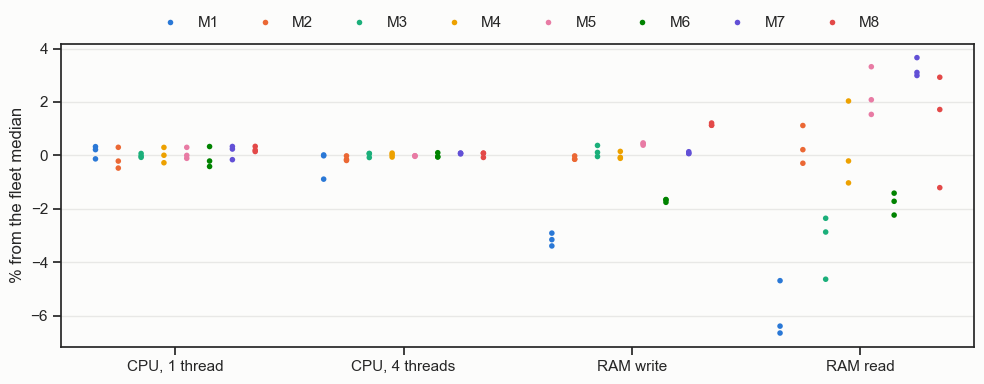

In [8]:
sp = res[res.stream == "speed"].assign(scope=lambda d: d.eid.map(lambda e: key_of[e][0]))
med = sp.groupby(["test", "scope"]).value.median()
fleet_med = med.groupby("test").median()
sp["pct"] = 100 * (sp.value / sp.test.map(fleet_med) - 1)

fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(sp, x="test", y="pct", hue="scope", order=list(TESTS), hue_order=present,
              palette=COLORS, dodge=True, jitter=0, size=4, ax=ax)
ax.set_xticks(range(len(TESTS)), list(TESTS.values()))
ax.set_xlabel("")
ax.set_ylabel("% from the fleet median")
ax.legend(ncol=len(present), loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
med.unstack("test")[list(TESTS)].reindex(present).round(1)

## Temperature through the run

SoC temperature (30 s mean) against time since the start of each run: the speed tests in the first minutes, the hour of
stress, then the cooldown. The curve should rise, settle to a plateau and fall back at the end. The Pi 4 starts
slowing itself down at 80 °C. A plateau that keeps climbing, or one far above the other scopes' at the same room
temperature, points to the cooling: fan, heatsink or airflow.

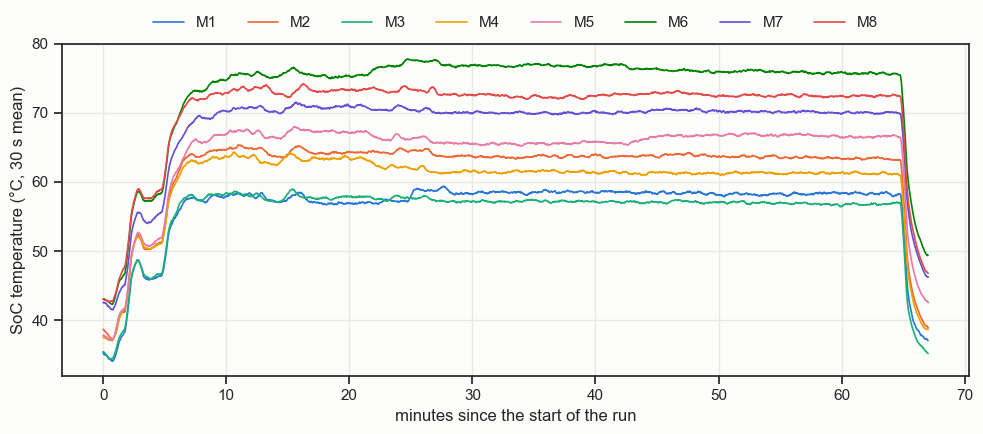

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (s, run), t in T.items():
    ax.plot(t.minutes, t.soc_temp_c.rolling(30, min_periods=1, center=True).mean(),
            color=COLORS[s], alpha=1 / run, label=s if run == 1 else None)
ax.set_xlabel("minutes since the start of the run")
ax.set_ylabel("SoC temperature (°C, 30 s mean)")
ax.legend(ncol=len(present), loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()

## Cooling

Left: the plateau, the mean SoC temperature over the last 10 min of stress, above the room temperature read by
the scope's T&H sensor at the start and end, so that scopes in warmer or cooler spots compare. Right: how fast
the board cools once the load stops: the time constant τ of an exponential fitted to the cooldown, decaying
towards the board's idle temperature before the run. τ is the time it takes to lose 63% of the excess heat;
a smaller τ is better cooling.

,,room_c,plateau_c,rise_c,cooldown_tau_s,fan_on_pct
scope,run,,,,,
M1,1,23.5,58.3,34.8,49.1,NaN
M2,1,23.6,63.4,39.8,42.4,98.8
M3,1,24.1,56.8,32.7,33.3,0.0
M4,1,23.3,61.2,38.0,41.2,98.9
M5,1,23.3,66.6,43.4,72.4,99.1
M6,1,23.8,75.8,51.9,80.8,100.0
M7,1,23.5,70.1,46.5,67.5,99.7
M8,1,23.3,72.5,49.1,64.0,100.0


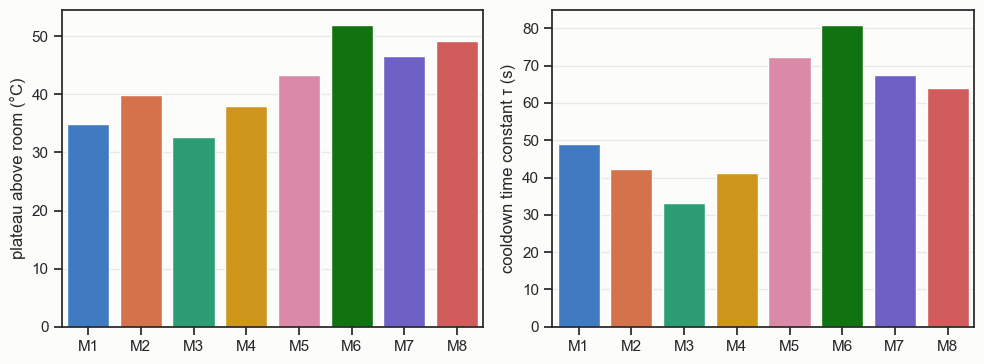

In [10]:
decay = lambda x, a, tau, c: c + a * np.exp(-x / tau)

def cooling(k, t):
    st, cd, idle = (t[t.phase == p] for p in ("stress", "cooldown", "settle"))
    room = [x["temp_c"] for x in (H[k]["system"].get("tandh_start"), H[k]["system"].get("tandh_end")) if x]
    plateau, c = st.soc_temp_c.tail(600).mean(), idle.soc_temp_c.mean()
    x, y = cd.elapsed_s - cd.elapsed_s.iloc[0], cd.soc_temp_c
    try:
        (a, tau), _ = curve_fit(lambda x, a, tau: decay(x, a, tau, c), x, y,
                                p0=(y.iloc[0] - c, 60), bounds=([0, 1], [100, 5000]))
    except (RuntimeError, ValueError):
        tau = np.nan
    return {"room_c": np.mean(room) if room else np.nan, "plateau_c": plateau,
            "rise_c": plateau - np.mean(room) if room else np.nan, "cooldown_tau_s": tau,
            "fan_on_pct": 100 * (st.fan > 0).mean() if st.fan.notna().any() else np.nan}

cool = pd.DataFrame([{"scope": k[0], "run": k[1], **cooling(k, t)} for k, t in T.items()]).set_index(["scope", "run"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, label in zip(axes, ["rise_c", "cooldown_tau_s"],
                          ["plateau above room (°C)", "cooldown time constant τ (s)"]):
    sns.barplot(cool.reset_index(), x="scope", y=col, hue="scope", order=present, palette=COLORS,
                legend=False, errorbar=None, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(label)
fig.tight_layout()
cool.round(1)

## Clock under load

Every clock reading during the stress phase. A healthy board holds its configured clock (`arm_freq`) the whole
time. Readings below it mean the firmware capped or throttled the clock, for heat or for a low supply voltage;
the throttle flags in the results say which.

,readings,min,median
scope,,,
M1,720,1800.0,1800.0
M2,720,1800.0,1800.0
M3,720,1800.0,1800.0
M4,720,1800.0,1800.0
M5,720,1800.0,1800.0
M6,720,1800.0,1800.0
M7,720,1800.0,1800.0
M8,720,1800.0,1800.0


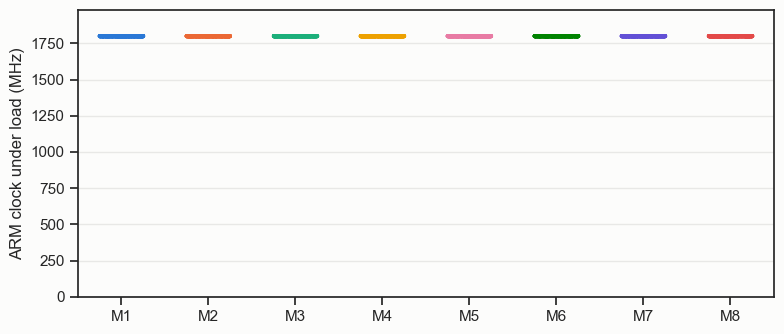

In [11]:
clk = pd.concat([t[t.phase == "stress"].dropna(subset=["arm_mhz"]).assign(scope=k[0])
                 for k, t in T.items()])
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.stripplot(clk, x="scope", y="arm_mhz", order=present, hue="scope", palette=COLORS,
              size=3, jitter=0.25, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("ARM clock under load (MHz)")
ax.set_ylim(0, 1.1 * clk.arm_mhz.max())
fig.tight_layout()
clk.groupby("scope").arm_mhz.agg(readings="size", min="min", median="median").reindex(present)

## Memory

Available memory and swap in use through the run. The memory worker holds a fixed 5 GiB during the stress
phase, so available memory drops by about that much and comes back at the end. Some swap while plenty of memory
is still available is normal Linux behaviour under this load. Swap that keeps growing, or available memory near
zero, means something else holds memory.

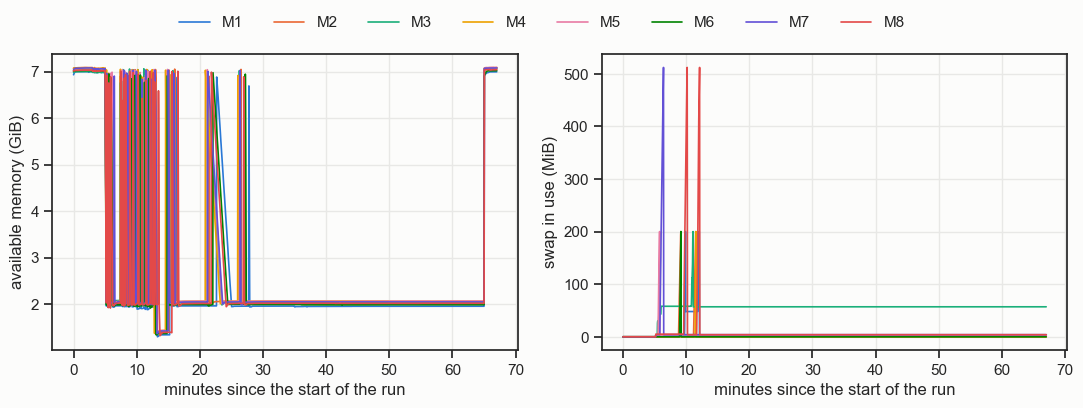

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for (s, run), t in T.items():
    axes[0].plot(t.minutes, t.mem_avail_mib / 1024, color=COLORS[s], alpha=1 / run,
                 label=s if run == 1 else None)
    axes[1].plot(t.minutes, t.swap_used_mib, color=COLORS[s], alpha=1 / run)
axes[0].set_ylabel("available memory (GiB)")
axes[1].set_ylabel("swap in use (MiB)")
for ax in axes:
    ax.set_xlabel("minutes since the start of the run")
fig.legend(ncol=len(present), loc="lower center", bbox_to_anchor=(0.5, 0.98))
fig.tight_layout()

## SSD temperature

The SSD's own temperature sensor, read once a minute, against time since the start of each run. The test puts no
load on the drive, so a rise is heat from the board next to it. Some drives report a fixed value instead of a live
reading; a flat line that never moves, at the same value on every drive of that model, is one of those. Runs
recorded before protocol `/2` have no SSD temperature.

In [13]:
have_ssd = {k: t.dropna(subset=["ssd_temp_c"]) for k, t in T.items() if t.ssd_temp_c.notna().any()}
if have_ssd:
    fig, ax = plt.subplots(figsize=(10, 4))
    for (s, run), t in have_ssd.items():
        ax.plot(t.minutes, t.ssd_temp_c, color=COLORS[s], alpha=1 / run, marker=".",
                label=s if run == 1 else None)
    ax.set_xlabel("minutes since the start of the run")
    ax.set_ylabel("SSD temperature (°C)")
    ax.legend(ncol=len(have_ssd), loc="lower center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout()
else:
    print("No SSD temperature in these runs.")

def ssd(k, t):
    v, st = t.ssd_temp_c.dropna(), t[t.phase == "stress"]
    if v.empty:
        return {"ssd_model": H[k].get("ssd", {}).get("model")}
    last = st[st.wall >= st.wall.max() - 600].ssd_temp_c.dropna()
    return {"ssd_model": H[k].get("ssd", {}).get("model"), "ssd_start_c": v.iloc[0],
            "ssd_plateau_c": last.mean(), "ssd_rise_c": last.mean() - v.iloc[0],
            "ssd_max_c": v.max(), "ssd_constant": v.nunique() == 1}

ssd_tab = pd.DataFrame([{"scope": k[0], "run": k[1], **ssd(k, t)} for k, t in T.items()]).set_index(["scope", "run"])
ssd_tab.round(1)

No SSD temperature in these runs.


,,ssd_model
scope,run,
M1,1,None
M2,1,None
M3,1,None
M4,1,None
M5,1,None
M6,1,None
M7,1,None
M8,1,None


## Results

One row per run, also written next to each run's data (`analysis/cpu_ram_health.yaml`) and exported to
`results/`. `wrong_results`: stress-ng log lines reporting a wrong result. `kernel_faults`: kernel errors during
the run (oops, segfault, lockup, RCU stall, SError); blank if the kernel log was not captured.
`throttle_during`: throttle flags raised during the run, or none. `ssd_*`: the SSD temperature summary from above. `clock_held_pct`: share of stress-phase clock readings
at `arm_freq`. `*_pct`: speed against the fleet median. `verdict` follows the acceptance table below;
`script_verdict` is what the script recorded on the scope.

In [14]:
NAMES = ["under-voltage", "frequency capped", "throttled", "soft temperature limit"]

def flags(t):
    """Throttle flags raised during the run: 'now' bits, and 'since boot' bits not set at the start."""
    v = t.throttled.dropna().astype(int).to_numpy()
    if not len(v):
        return "unknown"
    seen = np.bitwise_or.reduce(v)
    during = (seen & 0xF) | ((seen >> 16) & 0xF & ~(v[0] >> 16 & 0xF))
    return ", ".join(n for i, n in enumerate(NAMES) if during >> i & 1) or "none"

def row(k, r):
    h, t, s = H[k], T[k], H[k].get("stress") or {}
    st, arm = t[t.phase == "stress"], h["system"]["arm_freq"]
    log = find(r.dir, "stress-ng.log")
    kern = h.get("kernel", {})
    return {"scope": k[0], "run": k[1], "eid": r.eid, "serial": h["system"]["serial"],
            "standard": h["standard"], "stress_exit": s.get("exit_code"),
            "complete": not h["stopped_early"] and s.get("ran_s", 0) >= 0.95 * s.get("planned_s", 1),
            "wrong_results": sum(bool(re.search(r"\bfail:", l)) for l in open(log)) if log else np.nan,
            "kernel_faults": len(kern["faults"]) if kern.get("captured") else np.nan,
            "oom": len(kern.get("oom", [])), "throttle_during": flags(t),
            "clock_held_pct": 100 * (st.arm_mhz.dropna() >= 0.99 * arm).mean(),
            "soc_max_c": st.soc_temp_c.max(), "swap_max_mib": t.swap_used_mib.max(),
            "script_verdict": h.get("verdict")}

speed = sp.groupby(["eid", "test"]).value.median().unstack()[list(TESTS)]
speed_pct = (100 * (speed / fleet_med[list(TESTS)] - 1)).add_suffix("_pct")
fleet = pd.DataFrame([row(k, r) for k, r in runs.iterrows()]).set_index(["scope", "run"])
fleet = fleet.join(cool).join(ssd_tab).join(speed_pct, on="eid")

In [15]:
fail = (fleet.stress_exit == 2) | (fleet.wrong_results > 0) | (fleet.kernel_faults > 0)
incomplete = (~fleet.complete | ~fleet.stress_exit.isin([0, 2]) | (fleet.oom > 0)
              | fleet[[f"{t}_pct" for t in TESTS]].isna().any(axis=1))
warn = (~fleet.throttle_during.isin(["none"]) | (fleet.clock_held_pct < 99)
        | (fleet.soc_max_c >= HOT_C) | fleet.kernel_faults.isna())
fleet["verdict"] = np.select([fail, incomplete, warn], ["FAIL", "INCOMPLETE", "WARN"], "PASS")

os.makedirs(OUT, exist_ok=True)
fleet.round(2).to_csv(f"{OUT}/cpu_ram_health.csv")
for k, row_ in fleet.iterrows():                          # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(row_.eid), "cpu_ram_health.yaml"), "w") as f:
        yaml.safe_dump({c: (v.item() if hasattr(v, "item") else v) for c, v in row_.items()}, f)
fleet.drop(columns=["eid", "serial"]).round(1)

,,standard,stress_exit,complete,wrong_results,kernel_faults,oom,throttle_during,clock_held_pct,soc_max_c,swap_max_mib,...,plateau_c,rise_c,cooldown_tau_s,fan_on_pct,ssd_model,cpu_1t_pct,cpu_4t_pct,mem_write_4t_pct,mem_read_4t_pct,verdict
scope,run,,,,,,,,,,,,,,,,,,,,,
M1,1,True,0,True,0,0,0,none,100.0,60.4,200,...,58.3,34.8,49.1,NaN,None,0.2,-0.0,-3.2,-6.4,PASS
M2,1,True,0,True,0,0,0,none,100.0,66.7,200,...,63.4,39.8,42.4,98.8,None,-0.2,-0.2,-0.1,0.2,PASS
M3,1,True,0,True,0,0,0,none,100.0,60.9,200,...,56.8,32.7,33.3,0.0,None,-0.0,0.1,0.1,-2.9,PASS
M4,1,True,0,True,0,0,0,none,100.0,65.7,200,...,61.2,38.0,41.2,98.9,None,0.0,0.0,-0.1,-0.2,PASS
M5,1,True,0,True,0,0,0,none,100.0,69.1,200,...,66.6,43.4,72.4,99.1,None,-0.0,-0.0,0.4,2.1,PASS
M6,1,True,0,True,0,0,0,none,100.0,78.9,200,...,75.8,51.9,80.8,100.0,None,-0.2,-0.1,-1.7,-1.7,PASS
M7,1,True,0,True,0,0,0,none,100.0,73.0,512,...,70.1,46.5,67.5,99.7,None,0.2,0.1,0.1,3.1,PASS
M8,1,True,0,True,0,0,0,none,100.0,76.0,512,...,72.5,49.1,64.0,100.0,None,0.2,0.1,1.1,1.7,PASS


## Acceptance

Per board:

| Criterion | Level |
|---|---|
| stress-ng reports a wrong result (exit 2, or a `fail:` line in its log) | FAIL |
| A kernel error during the run | FAIL |
| The run stopped early, stress-ng exited with another error, memory ran out, or a speed test gave no result | INCOMPLETE |
| Under-voltage during the run | WARN: check the power supply and cable before the board |
| Clock capped or throttled, or below `arm_freq` in more than 1% of the stress-phase readings | WARN |
| SoC at 80 °C or more | WARN |
| Kernel log not captured | WARN |

FAIL means a board fault: replace the board, or rerun to confirm. INCOMPLETE means rerun.
Speed is not judged; it is compared across the fleet. Swap is reported but not judged: holding 5 GiB makes the
kernel swap briefly on healthy boards too. The script counted swap as a WARN in protocol `/1`, so for those runs
`script_verdict` can say WARN where `verdict` says PASS. SSD temperature is reported, not judged.

## Persistent records

This calibration writes 0 records to the scope. Its set-up step, `install_requirements()`, installs stress-ng and
sysbench with apt; nothing else on the scope changes.